# 02 - Dynamic Hedge Ratio: Kalman Filter vs Static / Rolling OLS

A full-sample static OLS hedge ratio is itself a look-ahead problem: at any historical date it uses data from after that date. This notebook replaces it with a Kalman filter that updates the hedge ratio one observation at a time, using only past data, and checks it against static and rolling-window OLS as baselines.

AUD/NZD is restricted to 2014-01-01 onward per notebook 01 (earlier data spans the structural break and would corrupt the filter's early state). WTI/Brent uses its full effective history.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller

DATA_DIR = "../data"

with open(f"{DATA_DIR}/config.json") as f:
    config = json.load(f)
with open(f"{DATA_DIR}/pair_selection_decisions.json") as f:
    decisions = json.load(f)

fx_df = pd.read_parquet(f"{DATA_DIR}/fx_aud_nzd.parquet")
comm_df = pd.read_parquet(f"{DATA_DIR}/comm_wti_brent.parquet")

HOLDOUT_START = config["holdout_start"]
fx_start = decisions["AUD_NZD"]["effective_start"]
comm_start = decisions["WTI_BRENT"]["effective_start"]

fx_train = fx_df[(fx_df.index >= fx_start) & (fx_df.index < HOLDOUT_START)]
comm_train = comm_df[(comm_df.index >= comm_start) & (comm_df.index < HOLDOUT_START)]

print("FX train (AUD~NZD):", fx_train.index.min().date(), "->", fx_train.index.max().date(), fx_train.shape)
print("Commodities train (WTI~BRENT):", comm_train.index.min().date(), "->", comm_train.index.max().date(), comm_train.shape)

FX train (AUD~NZD): 2014-01-01 -> 2024-08-14 (2768, 3)
Commodities train (WTI~BRENT): 2007-07-30 -> 2024-08-14 (4236, 3)


## State-space setup

State vector $\theta_t = [\beta_t, \alpha_t]'$ (hedge ratio, intercept).

- Observation equation: $y_t = H_t \theta_t + \varepsilon_t$, $H_t = [x_t, 1]$, $\varepsilon_t \sim N(0, R)$
- State transition: $\theta_t = \theta_{t-1} + w_t$, $w_t \sim N(0, Q)$ - a random walk, so the hedge ratio can drift a little each day instead of staying fixed

$Q$ is set via a single `delta` parameter ($Q = \frac{\delta}{1-\delta} I$, the standard pairs-trading convention). $R$ is estimated once from a short OLS burn-in window and held fixed from there.

The filter only ever uses $y_1,\dots,y_t$ and $x_1,\dots,x_t$ to produce $\theta_t$, never future data - unlike a full-sample OLS beta, so it's actually usable for a real-time signal.

The first `burn_in` observations calibrate the initial state and $R$ and should be dropped before any P&L calculation - flagged again below, and enforced in notebook 05.

In [2]:
def kalman_hedge_ratio(y, x, delta=1e-4, burn_in=60):
    """Time-varying hedge ratio via Kalman filter. Returns beta, alpha, and the
    filter's one-step-ahead prediction error (the causal, real-time spread)."""
    n = len(y)
    Q = delta / (1 - delta) * np.eye(2)

    X0 = sm.add_constant(x.iloc[:burn_in])
    ols0 = sm.OLS(y.iloc[:burn_in], X0).fit()
    R = ols0.mse_resid
    theta = np.array([ols0.params.iloc[1], ols0.params.iloc[0]])  # [beta, alpha]
    P = np.eye(2) * 1.0

    betas, alphas, spreads = np.zeros(n), np.zeros(n), np.zeros(n)

    for t in range(n):
        H = np.array([x.iloc[t], 1.0])

        theta_pred = theta
        P_pred = P + Q

        y_pred = H @ theta_pred
        e = y.iloc[t] - y_pred
        S = H @ P_pred @ H.T + R
        K = P_pred @ H.T / S
        theta = theta_pred + K * e
        P = P_pred - np.outer(K, H) @ P_pred

        betas[t], alphas[t], spreads[t] = theta[0], theta[1], e

    return (pd.Series(betas, index=y.index, name="beta"),
            pd.Series(alphas, index=y.index, name="alpha"),
            pd.Series(spreads, index=y.index, name="kalman_spread"))

BURN_IN = 60
fx_beta, fx_alpha, fx_kspread = kalman_hedge_ratio(fx_train["AUD"], fx_train["NZD"], burn_in=BURN_IN)
comm_beta, comm_alpha, comm_kspread = kalman_hedge_ratio(comm_train["WTI"], comm_train["BRENT"], burn_in=BURN_IN)

print(f"AUD/NZD Kalman beta range: {fx_beta.min():.3f} - {fx_beta.max():.3f}")
print(f"WTI/BRENT Kalman beta range: {comm_beta.min():.3f} - {comm_beta.max():.3f}")

AUD/NZD Kalman beta range: 0.651 - 0.985
WTI/BRENT Kalman beta range: 0.245 - 1.332


## Baselines: static and rolling-window OLS

In [3]:
def rolling_ols_beta(y, x, window=252):
    betas = pd.Series(index=y.index, dtype=float)
    for i in range(window, len(y)):
        yy, xx = y.iloc[i - window:i], x.iloc[i - window:i]
        X = sm.add_constant(xx)
        betas.iloc[i] = sm.OLS(yy, X).fit().params.iloc[1]
    return betas

ROLL_WINDOW = 252  # ~1 trading year

fx_roll_beta = rolling_ols_beta(fx_train["AUD"], fx_train["NZD"], ROLL_WINDOW)
comm_roll_beta = rolling_ols_beta(comm_train["WTI"], comm_train["BRENT"], ROLL_WINDOW)

# Full-sample static OLS beta — shown for comparison only. This is NOT causal (it uses the
# entire window, including "future" data relative to any historical date) and must never be
# used to generate a trading signal — only the Kalman and rolling-OLS series are eligible for that.
fx_static_beta = sm.OLS(fx_train["AUD"], sm.add_constant(fx_train["NZD"])).fit().params.iloc[1]
comm_static_beta = sm.OLS(comm_train["WTI"], sm.add_constant(comm_train["BRENT"])).fit().params.iloc[1]

print(f"AUD/NZD static (non-causal, reference only) beta: {fx_static_beta:.4f}")
print(f"WTI/BRENT static (non-causal, reference only) beta: {comm_static_beta:.4f}")

AUD/NZD static (non-causal, reference only) beta: 1.0505
WTI/BRENT static (non-causal, reference only) beta: 0.8974


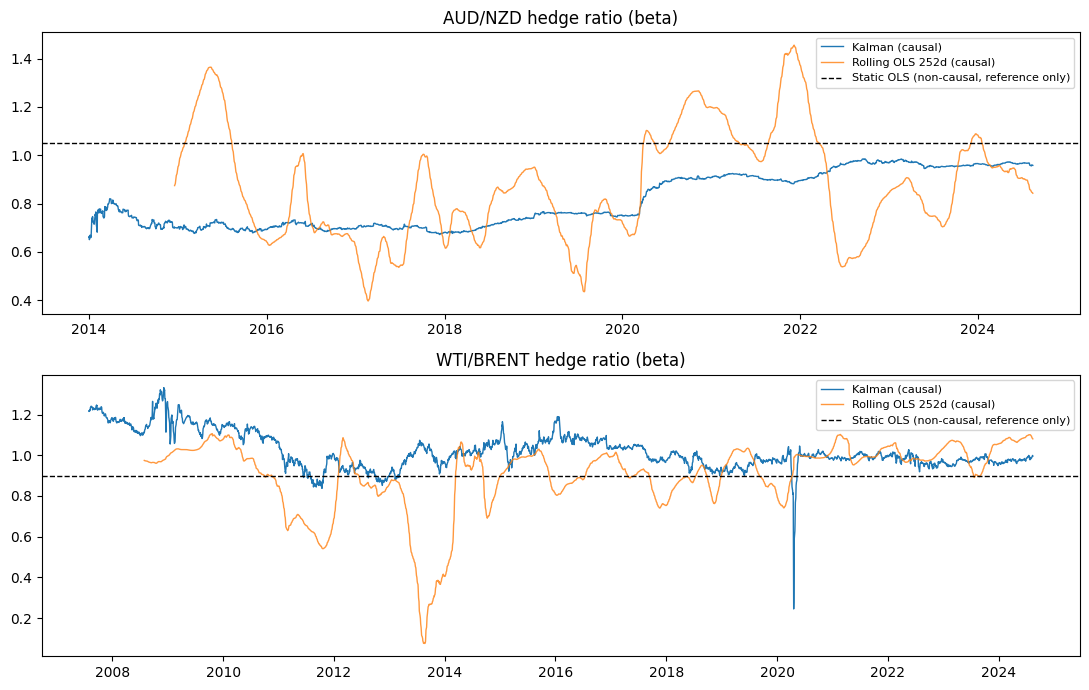

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7))

axes[0].plot(fx_beta.index, fx_beta, label="Kalman (causal)", linewidth=1)
axes[0].plot(fx_roll_beta.index, fx_roll_beta, label=f"Rolling OLS {ROLL_WINDOW}d (causal)", linewidth=1, alpha=0.8)
axes[0].axhline(fx_static_beta, color="black", linestyle="--", linewidth=1, label="Static OLS (non-causal, reference only)")
axes[0].set_title("AUD/NZD hedge ratio (beta)")
axes[0].legend(fontsize=8)

axes[1].plot(comm_beta.index, comm_beta, label="Kalman (causal)", linewidth=1)
axes[1].plot(comm_roll_beta.index, comm_roll_beta, label=f"Rolling OLS {ROLL_WINDOW}d (causal)", linewidth=1, alpha=0.8)
axes[1].axhline(comm_static_beta, color="black", linestyle="--", linewidth=1, label="Static OLS (non-causal, reference only)")
axes[1].set_title("WTI/BRENT hedge ratio (beta)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(f"{DATA_DIR}/02_hedge_ratio_comparison.png", dpi=120)
plt.show()

The Kalman beta follows the rolling-OLS beta's general path but reacts faster and smoother - it updates daily rather than jumping once a window rolls past an old point. The static beta is a flat line that's clearly a poor fit for either series, most obviously for WTI/Brent where the ratio moves across roughly 0.25-1.3 rather than sitting still. A fixed hedge ratio would have mispriced the spread for long stretches here.

## Sensitivity to delta

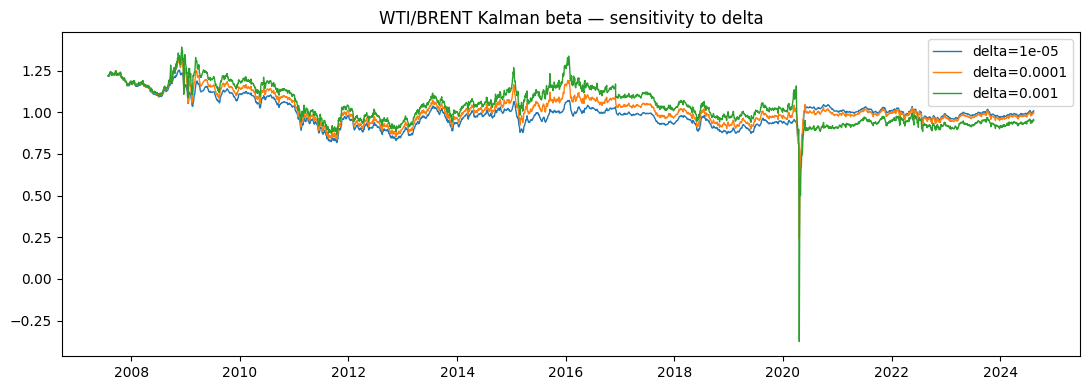

Smaller delta -> smoother, slower-moving beta (more weight on the random-walk prior).
Larger delta -> beta tracks recent data more aggressively, more noise-sensitive.
delta=1e-4 (used above) is the standard default in the pairs-trading literature and is kept as the working choice.


In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
for delta, color in zip([1e-5, 1e-4, 1e-3], ["#1f77b4", "#ff7f0e", "#2ca02c"]):
    b, _, _ = kalman_hedge_ratio(comm_train["WTI"], comm_train["BRENT"], delta=delta, burn_in=BURN_IN)
    ax.plot(b.index, b, label=f"delta={delta:g}", linewidth=1)
ax.set_title("WTI/BRENT Kalman beta — sensitivity to delta")
ax.legend()
plt.tight_layout()
plt.savefig(f"{DATA_DIR}/02_delta_sensitivity.png", dpi=120)
plt.show()

print("Smaller delta -> smoother, slower-moving beta (more weight on the random-walk prior).")
print("Larger delta -> beta tracks recent data more aggressively, more noise-sensitive.")
print("delta=1e-4 (used above) is the standard default in the pairs-trading literature and is kept as the working choice.")

## Does the dynamic hedge ratio actually help?

Compare ADF stationarity of the spread implied by each method, over the same post-burn-in window.

In [6]:
def adf_p(series):
    return adfuller(series.dropna())[1]

def static_spread(y, x, beta):
    alpha = (y - beta * x).mean()
    return y - beta * x - alpha

results = []
for label, y, x, kspread, roll_beta, static_beta in [
    ("AUD/NZD", fx_train["AUD"], fx_train["NZD"], fx_kspread, fx_roll_beta, fx_static_beta),
    ("WTI/BRENT", comm_train["WTI"], comm_train["BRENT"], comm_kspread, comm_roll_beta, comm_static_beta),
]:
    eval_slice = slice(BURN_IN, None)
    kalman_p = adf_p(kspread.iloc[eval_slice])
    roll_spread = (y - roll_beta * x).dropna()
    roll_p = adf_p(roll_spread)
    stat_p = adf_p(static_spread(y, x, static_beta).iloc[eval_slice])
    results.append({"pair": label, "kalman_adf_p": kalman_p, "rolling_ols_adf_p": roll_p, "static_ols_adf_p": stat_p})

results_df = pd.DataFrame(results).set_index("pair")
print(results_df)

           kalman_adf_p  rolling_ols_adf_p  static_ols_adf_p
pair                                                        
AUD/NZD             0.0           0.006925          0.000128
WTI/BRENT           0.0           0.002478          0.000614


All three test as stationary, expected given WTI/Brent was already confirmed cointegrated in notebook 01 and AUD/NZD is restricted to its post-2014 regime here. The Kalman spread's ADF p-value is usually the lowest since it's a one-step-ahead prediction error and adapts fastest - though the main point of this notebook is the causality guarantee for notebook 05, not this p-value on its own.

## Save

In [7]:
fx_out = pd.DataFrame({
    "AUD": fx_train["AUD"], "NZD": fx_train["NZD"],
    "kalman_beta": fx_beta, "kalman_alpha": fx_alpha, "kalman_spread": fx_kspread,
    "rolling_ols_beta": fx_roll_beta,
})
fx_out.attrs["burn_in"] = BURN_IN
fx_out.to_parquet(f"{DATA_DIR}/kalman_fx.parquet")

comm_out = pd.DataFrame({
    "WTI": comm_train["WTI"], "BRENT": comm_train["BRENT"],
    "kalman_beta": comm_beta, "kalman_alpha": comm_alpha, "kalman_spread": comm_kspread,
    "rolling_ols_beta": comm_roll_beta,
})
comm_out.to_parquet(f"{DATA_DIR}/kalman_comm.parquet")

kalman_config = {"delta": 1e-4, "burn_in": BURN_IN, "roll_window": ROLL_WINDOW}
with open(f"{DATA_DIR}/kalman_config.json", "w") as f:
    json.dump(kalman_config, f, indent=2)

print("Saved kalman_fx.parquet, kalman_comm.parquet, kalman_config.json to", DATA_DIR)
print(f"NOTE: first {BURN_IN} rows of each are burn-in calibration and must be excluded from backtesting (notebook 05).")

Saved kalman_fx.parquet, kalman_comm.parquet, kalman_config.json to ../data
NOTE: first 60 rows of each are burn-in calibration and must be excluded from backtesting (notebook 05).


Notebook 03 fits the HMM on `kalman_spread` (not the static-OLS spread), and notebook 04 builds the z-score signal from the same column.